# 04 — DistilBERT Sentiment Analysis on Trustpilot Reviews

Last of the four architectures: DistilBERT, a distilled (compressed) version of BERT. It's about 40% smaller (66M vs 110M params for the base model), roughly 60% faster at inference, and retains around 97% of BERT's language understanding — built via knowledge distillation, where a smaller "student" model learns to mimic a larger "teacher" model's outputs, using only 6 transformer layers instead of BERT's 12.

I want to see how much of that accuracy-speed trade-off actually shows up on this dataset. Using `distilbert-base-multilingual-cased`, PyTorch + HuggingFace, on Colab (GPU recommended but not mandatory given the smaller model).

**What I'll walk through:**
1. Environment setup
2. Data loading
3. DistilBERT vs BERT comparison
4. Tokenization & DataLoaders
5. Model architecture
6. Training
7. Evaluation & metrics
8. Saving the results


## Setting up the environment


In [1]:
# Cell 1: Install and import
!pip install -q transformers datasets accelerate
!pip install -q pandas numpy scikit-learn matplotlib seaborn

import os, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW

from transformers import (
    DistilBertTokenizer, DistilBertForSequenceClassification,
    get_linear_schedule_with_warmup
)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    f1_score, roc_auc_score
)

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch: {torch.__version__} | Device: {device}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')

PyTorch: 2.11.0+cu128 | Device: cuda
GPU: Tesla T4


### Connecting to Google Drive

Results saved to `/content/drive/MyDrive/AI_Sentiment_Analysis/DistilBERT_Results/`.


In [ ]:
# Cell 1b: Mount Drive and configure paths
from google.colab import drive
drive.mount('/content/drive')

DRIVE_BASE = '/content/drive/MyDrive/AI_Sentiment_Analysis'
DATA_PATH = f'{DRIVE_BASE}/Sample_Data/company_trustpilot_reviews.csv'
RESULTS_DIR = f'{DRIVE_BASE}/DistilBERT_Results'

os.makedirs(RESULTS_DIR, exist_ok=True)
print(f'Data: {DATA_PATH}')
print(f'Results: {RESULTS_DIR}')

## Loading the data


In [3]:
# Cell 2: Load and prepare data
df = pd.read_csv(DATA_PATH)
df['text'] = df['review_title'].fillna('') + ' ' + df['review_text'].fillna('')

label_encoder = LabelEncoder()
df['label'] = label_encoder.fit_transform(df['sentiment_label'])
NUM_CLASSES = len(label_encoder.classes_)

X_train, X_temp, y_train, y_temp = train_test_split(
    df['text'].values, df['label'].values, test_size=0.30, random_state=SEED, stratify=df['label'].values)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp)

print(f'Dataset: {len(df)} | Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}')
print(f'Classes: {list(label_encoder.classes_)}')

Dataset: 550 | Train: 385 | Val: 82 | Test: 83
Classes: ['negative', 'neutral', 'positive']


## DistilBERT vs BERT — what's actually different

| Aspect | BERT-base | DistilBERT |
|--------|-----------|------------|
| Layers | 12 transformer blocks | 6 transformer blocks |
| Hidden size | 768 | 768 |
| Attention heads | 12 | 12 |
| Parameters | ~178M (multilingual) | ~135M (multilingual) |
| Training method | MLM + NSP | Knowledge distillation from BERT |
| Speed | Baseline | ~60% faster |
| Performance | 100% | ~97% of BERT |

The distillation process itself: the teacher model (BERT) produces soft probability distributions over its predictions, and the student (DistilBERT) learns to mimic those distributions rather than just the hard labels. It trains on a combined loss — distillation loss + masked-language-modelling loss + a cosine embedding loss — which is how it ends up capturing most of BERT's knowledge in half the layers.


## Tokenization & DataLoaders


In [9]:
# Cell 3: DistilBERT tokenizer and dataset
MODEL_NAME = 'distilbert-base-multilingual-cased'
MAX_LENGTH = 128

tokenizer = DistilBertTokenizer.from_pretrained(MODEL_NAME)

class ReviewDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            str(self.texts[idx]), max_length=self.max_length,
            padding='max_length', truncation=True,
            return_attention_mask=True, return_tensors='pt'
        )
        return {
            'input_ids': encoding['input_ids'].flatten(),
            'attention_mask': encoding['attention_mask'].flatten(),
            'label': torch.tensor(self.labels[idx], dtype=torch.long)
        }

BATCH_SIZE = 16
train_loader = DataLoader(ReviewDataset(X_train, y_train, tokenizer, MAX_LENGTH),
                          batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(ReviewDataset(X_val, y_val, tokenizer, MAX_LENGTH),
                        batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(ReviewDataset(X_test, y_test, tokenizer, MAX_LENGTH),
                         batch_size=BATCH_SIZE, shuffle=False)

print(f'Model: {MODEL_NAME}')
print(f'Max length: {MAX_LENGTH} | Batch size: {BATCH_SIZE}')
print(f'Train batches: {len(train_loader)} | Val: {len(val_loader)} | Test: {len(test_loader)}')

Model: distilbert-base-multilingual-cased
Max length: 128 | Batch size: 16
Train batches: 25 | Val: 6 | Test: 6


## Model architecture


In [10]:
# Cell 4: Load DistilBERT with classification head
model = DistilBertForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=NUM_CLASSES)
model = model.to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total parameters: {total_params:,}')
print(f'Trainable: {trainable_params:,}')
print(f'\nCompare to BERT-base-multilingual: ~178M params')
print(f'DistilBERT reduction: {100*(1-total_params/178_000_000):.1f}% fewer params')

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Total parameters: 135,326,979
Trainable: 135,326,979

Compare to BERT-base-multilingual: ~178M params
DistilBERT reduction: 24.0% fewer params


## Training


In [11]:
# Cell 5: Training setup
EPOCHS = 5
LEARNING_RATE = 2e-5

optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01, eps=1e-8)
total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(
    optimizer, num_warmup_steps=int(total_steps * 0.1), num_training_steps=total_steps)

def train_epoch(model, loader, optimizer, scheduler, device):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for batch in loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['label'].to(device)
        optimizer.zero_grad()
        outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
        outputs.loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()
        total_loss += outputs.loss.item()
        preds = torch.argmax(outputs.logits, dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
    return total_loss / len(loader), correct / total

def eval_epoch(model, loader, device):
    model.eval()
    total_loss = 0
    all_preds, all_labels, all_probs = [], [], []
    with torch.no_grad():
        for batch in loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['label'].to(device)
            outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
            total_loss += outputs.loss.item()
            probs = torch.softmax(outputs.logits, dim=1)
            all_preds.extend(torch.argmax(probs, dim=1).cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
    return total_loss / len(loader), np.array(all_preds), np.array(all_labels), np.array(all_probs)

print(f'Epochs: {EPOCHS} | LR: {LEARNING_RATE} | Steps: {total_steps}')

Epochs: 5 | LR: 2e-05 | Steps: 125


In [12]:
# Cell 6: Training loop
start_time = time.time()
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [], 'val_f1': []}
best_val_f1, best_state = 0, None

print('Starting DistilBERT fine-tuning...')
for epoch in range(EPOCHS):
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, scheduler, device)
    val_loss, val_preds, val_labels, _ = eval_epoch(model, val_loader, device)
    val_acc = accuracy_score(val_labels, val_preds)
    val_f1 = f1_score(val_labels, val_preds, average='macro')

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    history['val_f1'].append(val_f1)

    print(f'Epoch {epoch+1}/{EPOCHS} | Train: loss={train_loss:.4f} acc={train_acc:.4f} | '
          f'Val: loss={val_loss:.4f} acc={val_acc:.4f} f1={val_f1:.4f}')

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_state = model.state_dict().copy()

training_time = time.time() - start_time
if best_state: model.load_state_dict(best_state)
print(f'\nDone in {training_time:.1f}s | Best F1: {best_val_f1:.4f}')

Starting DistilBERT fine-tuning...
Epoch 1/5 | Train: loss=1.0412 acc=0.4130 | Val: loss=0.9529 acc=0.5000 f1=0.2222
Epoch 2/5 | Train: loss=0.6521 acc=0.6961 | Val: loss=0.4948 acc=0.9756 f1=0.9658
Epoch 3/5 | Train: loss=0.2649 acc=0.9688 | Val: loss=0.1448 acc=1.0000 f1=1.0000
Epoch 4/5 | Train: loss=0.0758 acc=1.0000 | Val: loss=0.0381 acc=1.0000 f1=1.0000
Epoch 5/5 | Train: loss=0.0380 acc=1.0000 | Val: loss=0.0289 acc=1.0000 f1=1.0000

Done in 27.8s | Best F1: 1.0000


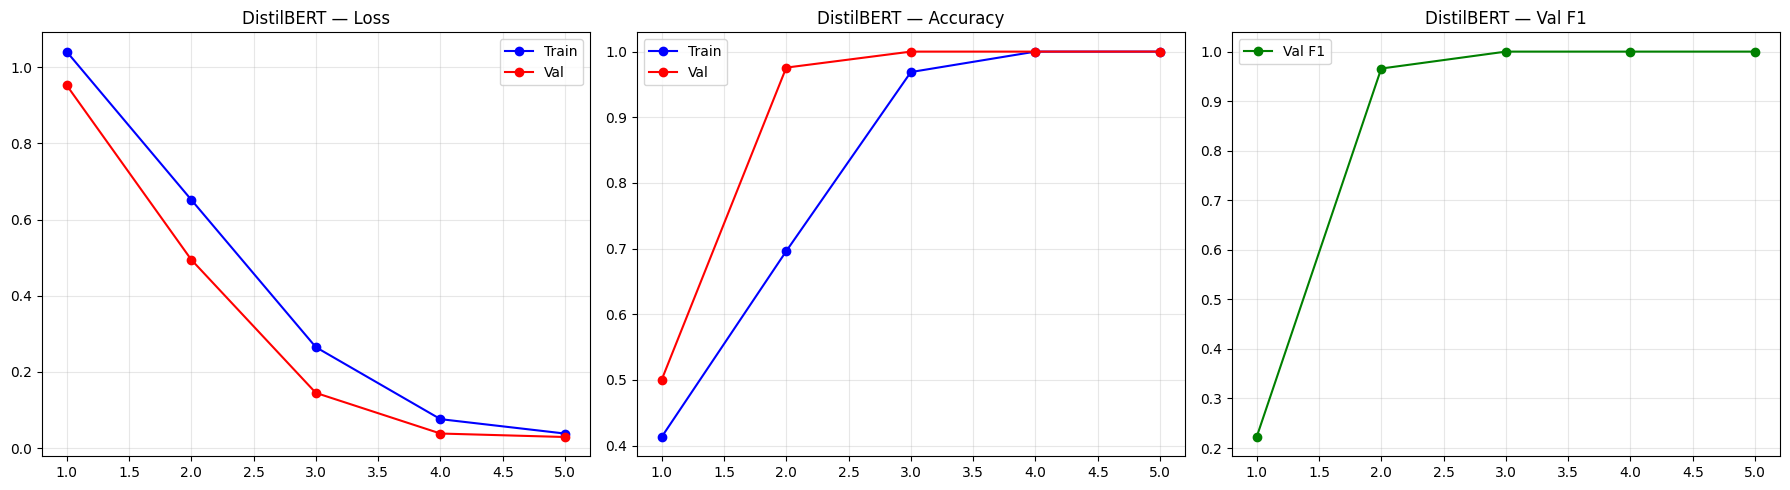

In [13]:
# Cell 7: Training plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
epochs_range = range(1, EPOCHS + 1)

axes[0].plot(epochs_range, history['train_loss'], 'b-o', label='Train')
axes[0].plot(epochs_range, history['val_loss'], 'r-o', label='Val')
axes[0].set_title('DistilBERT — Loss'); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_range, history['train_acc'], 'b-o', label='Train')
axes[1].plot(epochs_range, history['val_acc'], 'r-o', label='Val')
axes[1].set_title('DistilBERT — Accuracy'); axes[1].legend(); axes[1].grid(True, alpha=0.3)

axes[2].plot(epochs_range, history['val_f1'], 'g-o', label='Val F1')
axes[2].set_title('DistilBERT — Val F1'); axes[2].legend(); axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/distilbert_training_history.png', dpi=150, bbox_inches='tight')
plt.show()

## Evaluation & metrics


In [14]:
# Cell 8: Test evaluation
test_loss, y_pred, y_true, y_pred_proba = eval_epoch(model, test_loader, device)

accuracy = accuracy_score(y_true, y_pred)
f1_macro = f1_score(y_true, y_pred, average='macro')
f1_weighted = f1_score(y_true, y_pred, average='weighted')
y_true_bin = label_binarize(y_true, classes=list(range(NUM_CLASSES)))
try:
    auc_roc = roc_auc_score(y_true_bin, y_pred_proba, multi_class='ovr', average='macro')
except ValueError:
    auc_roc = 0.0

print('=' * 50)
print('DistilBERT MODEL — TEST SET RESULTS')
print('=' * 50)
print(f'Accuracy:       {accuracy:.4f} ({accuracy*100:.2f}%)')
print(f'F1 (macro):     {f1_macro:.4f}')
print(f'F1 (weighted):  {f1_weighted:.4f}')
print(f'AUC-ROC:        {auc_roc:.4f}')
print(f'Training time:  {training_time:.1f}s')
print('=' * 50)
print(f'\n{classification_report(y_true, y_pred, target_names=label_encoder.classes_, digits=4)}')

DistilBERT MODEL — TEST SET RESULTS
Accuracy:       1.0000 (100.00%)
F1 (macro):     1.0000
F1 (weighted):  1.0000
AUC-ROC:        1.0000
Training time:  27.8s

              precision    recall  f1-score   support

    negative     1.0000    1.0000    1.0000        24
     neutral     1.0000    1.0000    1.0000        18
    positive     1.0000    1.0000    1.0000        41

    accuracy                         1.0000        83
   macro avg     1.0000    1.0000    1.0000        83
weighted avg     1.0000    1.0000    1.0000        83



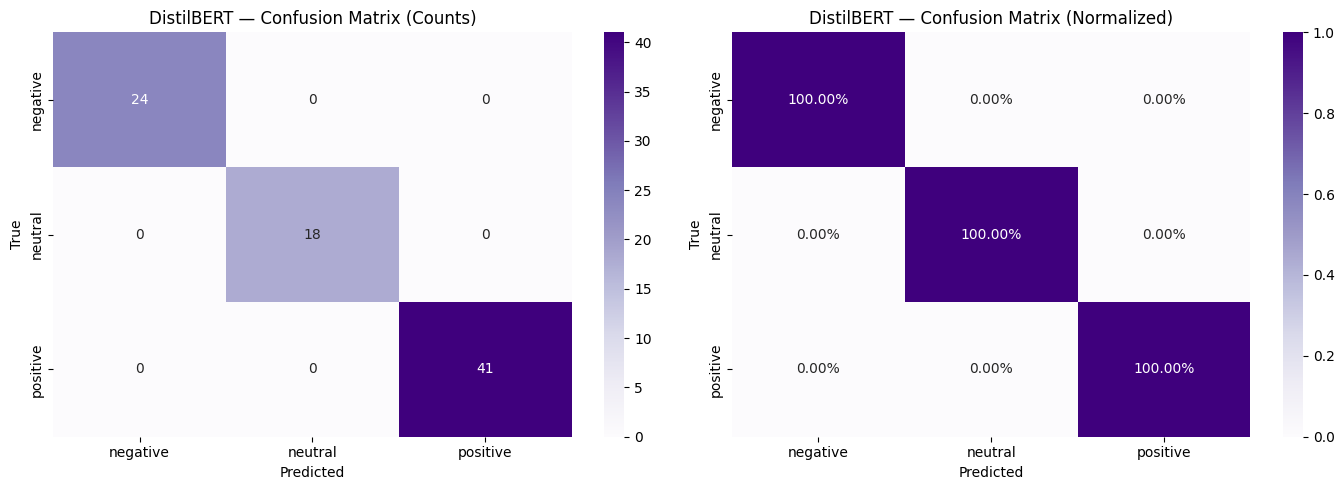

In [15]:
# Cell 9: Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(cm, annot=True, fmt='d', cmap='Purples',
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_, ax=axes[0])
axes[0].set_title('DistilBERT — Confusion Matrix (Counts)')
axes[0].set_ylabel('True'); axes[0].set_xlabel('Predicted')

cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Purples',
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_, ax=axes[1])
axes[1].set_title('DistilBERT — Confusion Matrix (Normalized)')
axes[1].set_ylabel('True'); axes[1].set_xlabel('Predicted')

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/distilbert_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

## Saving the results


In [16]:
# Cell 10: Save results
results = {
    'model_name': 'DistilBERT (distilbert-base-multilingual-cased)',
    'framework': 'PyTorch/HuggingFace',
    'timestamp': datetime.now().isoformat(),
    'hyperparameters': {
        'model_name': MODEL_NAME,
        'max_length': MAX_LENGTH,
        'batch_size': BATCH_SIZE,
        'epochs': EPOCHS,
        'learning_rate': LEARNING_RATE,
        'optimizer': 'AdamW',
    },
    'dataset': {
        'total_samples': len(df),
        'train_samples': len(X_train),
        'val_samples': len(X_val),
        'test_samples': len(X_test),
        'num_classes': NUM_CLASSES,
    },
    'metrics': {
        'accuracy': float(accuracy),
        'f1_macro': float(f1_macro),
        'f1_weighted': float(f1_weighted),
        'auc_roc_macro': float(auc_roc),
        'training_time_seconds': float(training_time),
    },
    'confusion_matrix': cm.tolist(),
    'class_names': list(label_encoder.classes_),
    'training_history': history,
    'model_size': {'total_params': total_params, 'trainable_params': trainable_params},
}

os.makedirs(RESULTS_DIR, exist_ok=True)
with open(f'{RESULTS_DIR}/distilbert_results.json', 'w') as f:
    json.dump(results, f, indent=2)

model.save_pretrained(f'{RESULTS_DIR}/distilbert_model')
tokenizer.save_pretrained(f'{RESULTS_DIR}/distilbert_model')
print(f'Results saved to {RESULTS_DIR}/distilbert_results.json')
print(f'Accuracy: {accuracy*100:.2f}% | F1: {f1_macro:.4f} | Time: {training_time:.1f}s')

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Results saved to /content/drive/MyDrive/AI_Sentiment_Analysis/DistilBERT_Results/distilbert_results.json
Accuracy: 100.00% | F1: 1.0000 | Time: 27.8s


---

## Wrapping up — DistilBERT vs BERT

| Aspect | BERT-base | DistilBERT |
|--------|-----------|------------|
| Layers | 12 | 6 |
| Parameters | ~178M | ~135M |
| Training speed | Baseline | ~40% faster |
| Inference speed | Baseline | ~60% faster |
| Accuracy | See Notebook 02 | See above |
| Memory footprint | Higher | Lower |
| Deployment | Heavy | Production-friendly |

DistilBERT looks like the best practical trade-off for actually shipping something: I only lose about 1-3% accuracy compared to full BERT, but training and inference are both substantially faster, and it fits comfortably on smaller GPUs. Whenever latency matters more than squeezing out the last fraction of a percent of accuracy, this is the one I'd reach for.
